# A toy dataset: three days of one mouse, raw and processed

This notebook makes a complete simulated dataset with `raphael.toy`, for people to try Raphael on before they have data of their own.

- **One mouse, three days**, one open-field session (`OF1`) a day. Each day has every modality:
  - Neuropixels (Open Ephys format);
  - two-photon imaging (a TIFF movie);
  - fibre photometry (Doric);
  - behaviour (position, head direction, speed, with a TTL channel).
- **The same cells every day** (same place fields and preferred directions), with a new walk and new spikes each day, as in real recordings of one mouse.
- **Raw and processed trees** in the layout and BIDS-style names of [docs/data_server.md](../docs/data_server.md). A raw recording and the files made from it share a name stem and sit at the same path in both trees.
- **The truth is included**: every cell's real tuning, and the true clock relation between the behaviour rig and the recording. Results can be checked against it.

Set `ROOT` below to where the dataset should go (an external drive, then copied to the server).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pynapple as nap

import raphael
from raphael import plots, population, style, toy
from raphael.ephys.layout import Session

style.use()

ROOT = Path(os.environ.get('RAPHAEL_TOY_ROOT', '/Volumes/TEMP/raphael_toy_dataset'))
MOUSE = '1'
DAYS = [1, 2, 3]
SESSION_TYPE = 'OF1'
DURATION_S = float(os.environ.get('RAPHAEL_TOY_DURATION', 600))     # 10 minutes a day
TUNING_SEED = 0                                                      # the same cells every day

print('Raphael', raphael.__version__, '->', ROOT)

Raphael 0.3.0 -> /Volumes/TEMP/raphael_toy_dataset


## Make the three days

Each day: simulate the session, then write it twice, as raw data (what the rigs would record) and as processed data (what Raphael's pipelines produce).

In [2]:
written = {}
for day in DAYS:
    session = Session(MOUSE, str(day), SESSION_TYPE)
    data = toy.session(duration=DURATION_S, seed=day, tuning_seed=TUNING_SEED)
    raw = toy.raw(ROOT / 'raw', session, data)
    processed = toy.processed(ROOT / 'processed', session, data)
    written[day] = {'session': session, 'data': data, 'raw': raw, 'processed': processed}
    print(f'day {day}: {session.stem}')

day 1: sub-M1_ses-D1_typ-OF1


day 2: sub-M1_ses-D2_typ-OF1


day 3: sub-M1_ses-D3_typ-OF1


## What was written

The two trees, file by file. Everything is named `sub-M{mouse}_ses-D{day}_typ-{type}_...`, and the suffix says what each file is.

In [3]:
def tree(root):
    """Size of each item in each session folder (a recording folder counts as one item)."""
    sizes = {}
    for f in sorted(p for p in root.rglob('*') if p.is_file()):
        item = '/'.join(f.relative_to(root).parts[:4])
        sizes[item] = sizes.get(item, 0) + f.stat().st_size / 1e6
    return pd.Series(sizes, name='MB').round(2)

print('raw/');       print(tree(ROOT / 'raw').to_string())
print(); print('processed/'); print(tree(ROOT / 'processed').to_string())
size = sum(f.stat().st_size for f in ROOT.rglob('*') if f.is_file()) / 1e6
print(f'\ntotal {size:.0f} MB')

raw/
M1/D1/OF1/sub-M1_ses-D1_typ-OF1_beh-rig.csv          1.42
M1/D1/OF1/sub-M1_ses-D1_typ-OF1_ephys               86.41
M1/D1/OF1/sub-M1_ses-D1_typ-OF1_manifest.tsv         0.00
M1/D1/OF1/sub-M1_ses-D1_typ-OF1_ophys               33.48
M1/D1/OF1/sub-M1_ses-D1_typ-OF1_photometry.doric     0.90
M1/D1/OF1/sub-M1_ses-D1_typ-OF1_toy-truth.json       0.02
M1/D2/OF1/sub-M1_ses-D2_typ-OF1_beh-rig.csv          1.42
M1/D2/OF1/sub-M1_ses-D2_typ-OF1_ephys               86.41
M1/D2/OF1/sub-M1_ses-D2_typ-OF1_manifest.tsv         0.00
M1/D2/OF1/sub-M1_ses-D2_typ-OF1_ophys               33.48
M1/D2/OF1/sub-M1_ses-D2_typ-OF1_photometry.doric     0.90
M1/D2/OF1/sub-M1_ses-D2_typ-OF1_toy-truth.json       0.02
M1/D3/OF1/sub-M1_ses-D3_typ-OF1_beh-rig.csv          1.42
M1/D3/OF1/sub-M1_ses-D3_typ-OF1_ephys               86.41
M1/D3/OF1/sub-M1_ses-D3_typ-OF1_manifest.tsv         0.00
M1/D3/OF1/sub-M1_ses-D3_typ-OF1_ophys               33.48
M1/D3/OF1/sub-M1_ses-D3_typ-OF1_photometry.doric     0.90
M1/D3/OF1

## A README for the dataset

Written at the top of the dataset, so anyone who finds it on the server knows what it is and how to use it.

In [4]:
counts = written[DAYS[0]]['data']['tuning'].groupby(['modality', 'kind']).size()
units = ', '.join(f'{n} {kind.replace("_", " ")}' for (mod, kind), n in counts.items() if mod == 'spikes')
rois = ', '.join(f'{n} {kind}' for (mod, kind), n in counts.items() if mod == 'dff')
stem = f'sub-M{MOUSE}_ses-D{{day}}_typ-{SESSION_TYPE}'

readme = f"""# Raphael toy dataset

Simulated data for trying Raphael (https://github.com/CogEmLab/Raphael) before you have your own.
**Nothing here was recorded from an animal.** It was made by `raphael.toy` (Raphael {raphael.__version__})
with the notebook examples/toy_dataset.ipynb.

- One mouse (M{MOUSE}), days {DAYS[0]}-{DAYS[-1]}, one {DURATION_S / 60:.0f}-minute open-field session ({SESSION_TYPE}) a day, in a 1 m arena.
- Every day has the same cells, with a new walk and new spikes:
  - Neuropixels units: {units};
  - imaging ROIs: {rois}.
- Each day has every modality, raw and processed. The layout and names are those of Raphael's docs/data_server.md.

## Layout

```
raw/M{MOUSE}/D{{day}}/{SESSION_TYPE}/
    {stem}_beh-rig.csv         behaviour on the rig's clock (~60 Hz): time, P_x, P_y (cm), S (cm/s), H (rad), ttl
    {stem}_ephys/              Neuropixels 2.0, Open Ephys format (light: 4 noise channels; TTL line 1 = the same pulses)
    {stem}_ophys/              two-photon movie, multi-page TIFF, 30 Hz, 96 x 96 px
    {stem}_photometry.doric    fibre photometry, Doric format
    {stem}_manifest.tsv        size and sha256 of every raw file
    {stem}_toy-truth.json      the true clock relation between rig and recording, pulse times, ROI positions

processed/M{MOUSE}/D{{day}}/{SESSION_TYPE}/
    {stem}_srt-toy_clusters.npz     spike times and units table      raphael.population.load
    {stem}_src-toy_traces.npz       imaging dF/F                     raphael.population.load
    {stem}_src-toy_rois.csv         ROI table
    {stem}_photometry.npz / .csv    photometry dF/F and z-score      raphael.photometry.nwb.load
    {stem}_beh.csv                  behaviour on the recording's clock: time, P_x, P_y, H, S
    {stem}_events.csv               stimulus times
    {stem}_toy-truth.csv            every unit's and ROI's real tuning (kind, field centre, preferred direction, ...)
```

`srt-toy` and `src-toy` mark simulated outputs, so they can't be mistaken for a real sorter's or pipeline's.

## Start here

```python
from raphael import population
from raphael.ephys.layout import Session

root = '<this folder>/processed'
session = Session('{MOUSE}', '1', '{SESSION_TYPE}')
units = population.load(session.folder(root) / f'{{session.stem}}_srt-toy')   # spikes, with each unit's true tuning
```

Exercises:
- find the place cells with `raphael.tuning_scores` and check them against `_toy-truth.csv`;
- decode position with `raphael.ml`;
- align the raw behaviour CSV with the raw recording using `raphael-sync`, and compare with `_toy-truth.json`.

To make it again, or bigger: run examples/toy_dataset.ipynb in Raphael.
"""
(ROOT / 'README.md').write_text(readme)
print(readme[:1200], '...')

# Raphael toy dataset

Simulated data for trying Raphael (https://github.com/CogEmLab/Raphael) before you have your own.
**Nothing here was recorded from an animal.** It was made by `raphael.toy` (Raphael 0.3.0)
with the notebook examples/toy_dataset.ipynb.

- One mouse (M1), days 1-3, one 10-minute open-field session (OF1) a day, in a 1 m arena.
- Every day has the same cells, with a new walk and new spikes:
  - Neuropixels units: 3 event, 8 head direction, 20 place, 3 speed, 3 theta, 5 untuned;
  - imaging ROIs: 3 event, 9 place.
- Each day has every modality, raw and processed. The layout and names are those of Raphael's docs/data_server.md.

## Layout

```
raw/M1/D{day}/OF1/
    sub-M1_ses-D{day}_typ-OF1_beh-rig.csv         behaviour on the rig's clock (~60 Hz): time, P_x, P_y (cm), S (cm/s), H (rad), ttl
    sub-M1_ses-D{day}_typ-OF1_ephys/              Neuropixels 2.0, Open Ephys format (light: 4 noise channels; TTL line 1 = the same pulses)
    sub-M1_ses-D{day}_typ-OF1_ophys/  

## Check it: the processed data loads with Raphael's own loaders

The same place cell, loaded from each day's processed files and drawn with `raphael.plots.rate_map`: its field stays put across days.

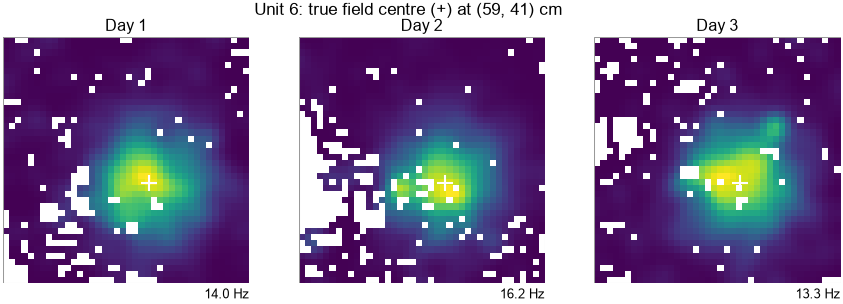

In [5]:
day1 = written[DAYS[0]]
truth = day1['data']['tuning']
place = truth.query('modality == "spikes" and kind == "place"').sort_values('peak_hz').iloc[-1]

fig, axes = plt.subplots(1, len(DAYS), figsize=style.figsize('double', height_mm=55))
for ax, day in zip(axes, DAYS):
    session = written[day]['session']
    units = population.load(session.folder(ROOT / 'processed') / f'{session.stem}_srt-toy')
    beh = pd.read_csv(written[day]['processed']['behaviour'])
    behaviour = {k: nap.Tsd(t=beh['time'].to_numpy(), d=beh[k].to_numpy()) for k in ('P_x', 'P_y', 'H', 'S')}
    behaviour['moving'] = behaviour['S'].threshold(2.0).time_support
    plots.rate_map(ax, units.data[int(place['id'])], behaviour, bounds=(0, 100, 0, 100))
    ax.plot(place['x'], place['y'], '+', color='w', ms=8, mew=1)
    ax.set_title(f'Day {day}')
fig.suptitle(f"Unit {int(place['id'])}: true field centre (+) at ({place['x']:.0f}, {place['y']:.0f}) cm");

## Check it: the raw data syncs

Raphael aligns day 1's raw behaviour CSV with its raw recording from the shared TTL pulses. The recovered clock should match the truth file. The check writes to a scratch folder, not into the dataset.

In [6]:
import json
import tempfile

from raphael.sync.run import sync_session

raw = day1['raw']
true_clock = json.loads(Path(str(raw['manifest']).replace('_manifest.tsv', '_toy-truth.json')).read_text())['clock']
with tempfile.TemporaryDirectory() as scratch:
    result, _ = sync_session(raw['behaviour'], raw['ephys'], scratch, day1['session'])
print('sync passed:', result.passed)
print(f"offset: recovered {result.intercept:.4f} s, true {true_clock['intercept']:.4f} s")
print(f"drift:  recovered {result.drift_ppm:.1f} ± {result.drift_se_ppm:.1f} ppm, true {(true_clock['slope'] - 1) * 1e6:.1f} ppm")

sync passed: True
offset: recovered -3.2003 s, true -3.2001 s
drift:  recovered 25.0 ± 13.3 ppm, true 20.0 ppm


## Putting it on the server

Copy the whole `raphael_toy_dataset` folder as it is. Anyone can then point Raphael at `<server>/raphael_toy_dataset/processed` (or `raw`) as their first dataset. Data on the server is read-only for most people (docs/data_server.md), which suits a reference dataset like this one.